In [1]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import matplotlib
from pathlib import Path
from matplotlib import rcParams
import plotting_functions

In [2]:
# Define base directories
# Base paths
base_auc_ = "data_Figs/Fig_AUC_all_subtypes"
base_fix_ = "data_Figs/Fig_Fix_prob_all_subtypes"


In [4]:
# Load Data
data_3HA = plotting_functions.load_data("H3N2", "HA",base_auc_,base_fix_)
data_3NA = plotting_functions.load_data("H3N2", "NA",base_auc_,base_fix_)
data_1HA = plotting_functions.load_data("H1N1", "HA",base_auc_,base_fix_)
data_1NA = plotting_functions.load_data("H1N1", "NA",base_auc_,base_fix_)


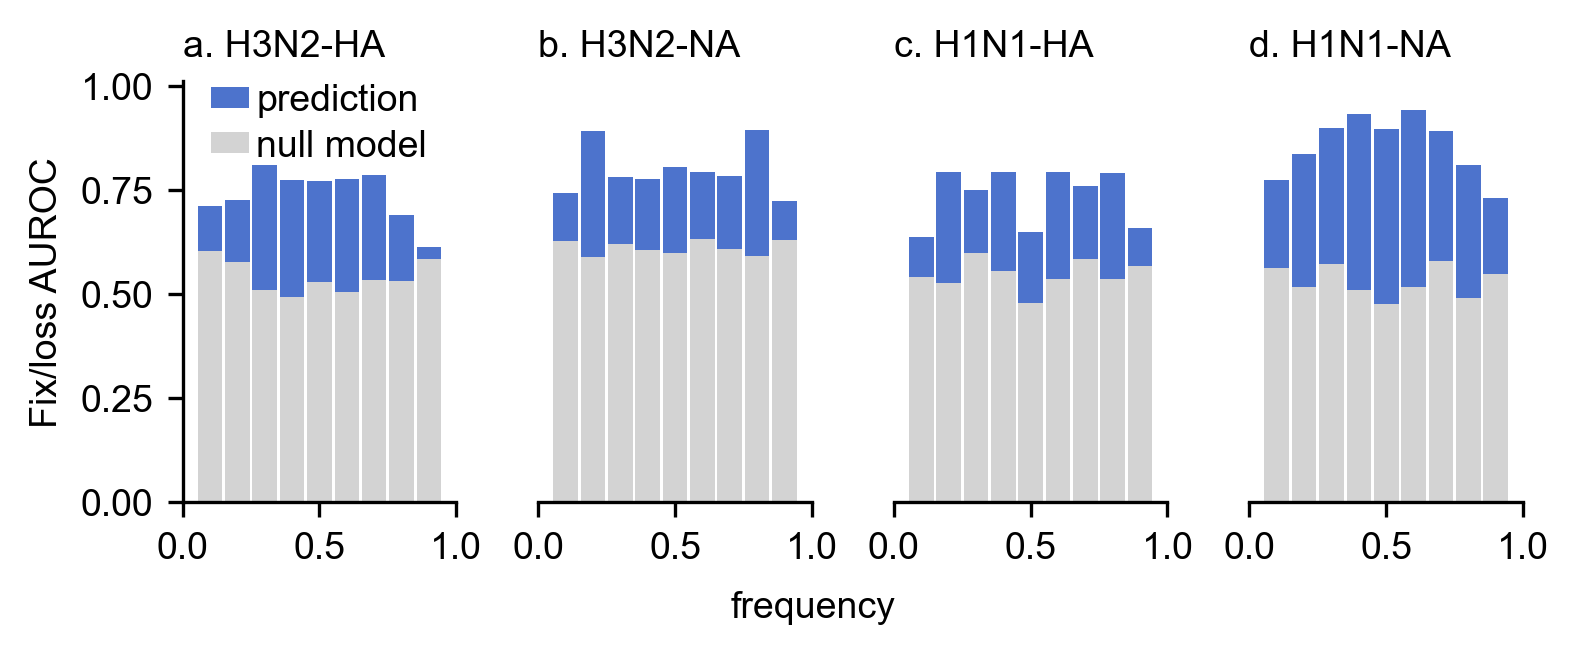

In [6]:

# Create 1 row, 4 column layout

fig, axs = plt.subplots(1, 4, figsize=plotting_functions.get_figsize("horizontal"), dpi=300)

# List of axes and labels
auc_data = [
    (data_3HA, "a. H3N2-HA"),
    (data_3NA, "b. H3N2-NA"),
    (data_1HA, "c. H1N1-HA"),
    (data_1NA, "d. H1N1-NA"),
]

# Generate AUC plots directly on layout axes
for i, (data, title) in enumerate(auc_data):
    ax = axs[i]
    plotting_functions.plot_auc_bar(data, title, ax=ax)  # <- pass ax explicitly

    # Only keep legend in the first subplot
    if i != 0:
        ax.legend().remove()
        ax.set_ylabel("")
        ax.set_yticklabels([])
        ax.set_yticks([])
        ax.spines['left'].set_visible(False)  # Removes y-axis line
    # Hide y-axis on all but the first
    if i != 0:
        ax.set_ylabel("")
        ax.set_yticklabels([])
        ax.tick_params(axis='y', length=0)
        
    # Align title to the left
    ax.set_title(title, loc='left')
plt.subplots_adjust(left=0.1, right=0.95, top=0.95, bottom=0.15, wspace=0.3, hspace=0.4)

# Adjust spacing
#fig.tight_layout(pad=1)
fig.text(0.5, -0.05, 'frequency', ha='center', va='center')

# Show or save
fig.savefig("AUC_all_proteins.pdf", bbox_inches="tight")
plt.show()

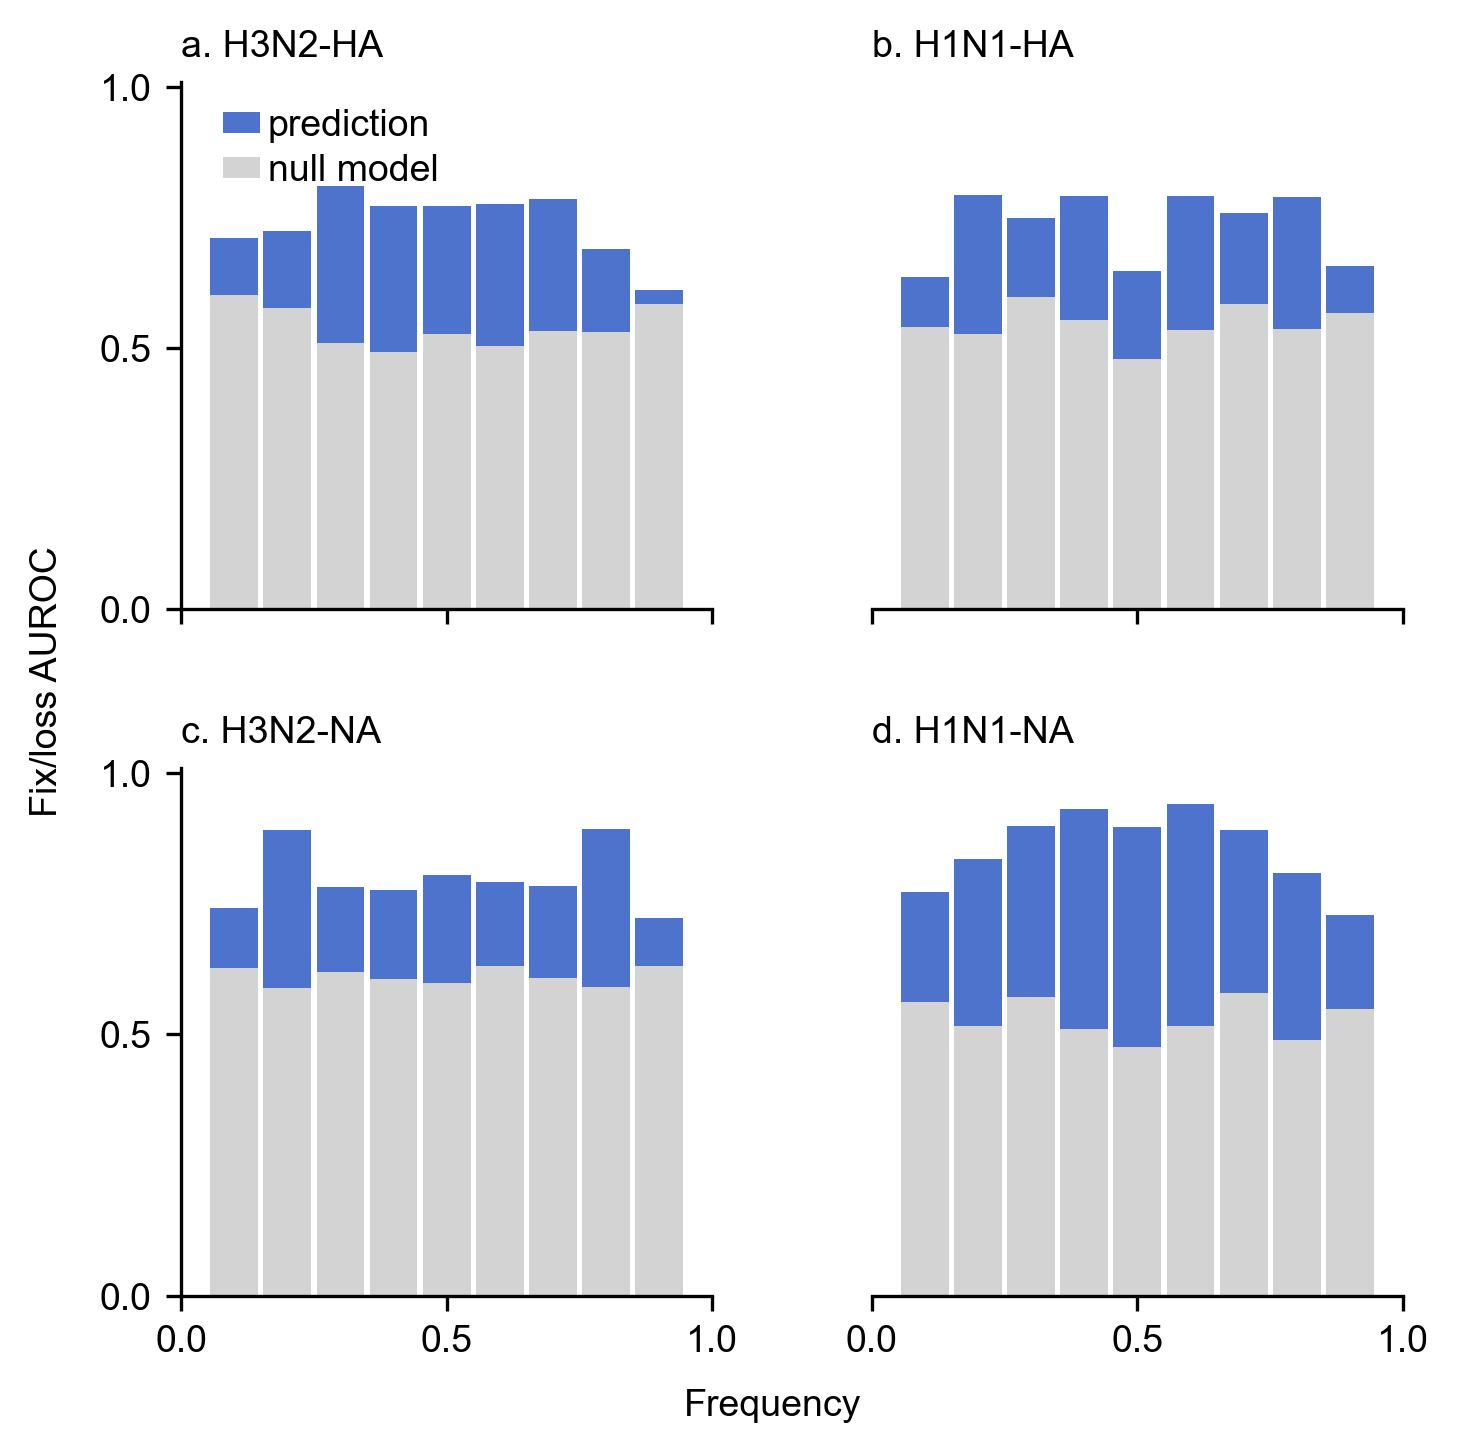

In [12]:
fig, axes = plt.subplots(
    2, 2,
    figsize=plotting_functions.get_figsize("square"),
    sharey=True,
    gridspec_kw={"width_ratios": [1, 1]},
    dpi=300
)
axes = axes.flatten()

auc_data = [
    (data_3HA, "a. H3N2-HA"),  # i = 0
    (data_1HA, "b. H1N1-HA"),  # i = 1
    (data_3NA, "c. H3N2-NA"),  # i = 2
    (data_1NA, "d. H1N1-NA"),  # i = 3
]

for i, (ax, (data, title)) in enumerate(zip(axes, auc_data)):
    plotting_functions.plot_auc_bar(data, title, ax=ax)
    ax.set_title(title, loc='left')

    # Remove legend from all but first
    if i != 0:
        ax.legend().remove()

    if i % 2 == 1:
        # Right-hand plots: hide y-axis
        ax.set_ylabel("")
        ax.tick_params(axis='y', which='both', left=False, right=False)
        ax.spines['left'].set_visible(False)
    else:
        # Left-hand plots: show y-axis
        ax.tick_params(axis='y', which='both', left=True, right=False)
        ax.spines['left'].set_visible(True)
        # No need to set y-tick labels manually unless customizing

    # Remove x-axis labels for top row
    if i < 2:
        ax.set_xlabel("")
        ax.set_xticks([0.0, 0.5, 1.0])
        ax.set_xticklabels([])  # Hide labels but keep ticks
    else:
        ax.set_xticks([0.0, 0.5, 1.0])

# Shared labels
fig.text(0.5, 0.04, 'Frequency', ha='center', va='center')
fig.text(0.04, 0.5, 'Fix/loss AUROC', ha='center', va='center', rotation='vertical')

plt.subplots_adjust(wspace=0.3, hspace=0.3)

fig.savefig("AUC_all_proteins_square_layout.pdf", bbox_inches="tight")
plt.show()